<a href="https://colab.research.google.com/github/LGLV-Ciencia-de-Datos/Bioinformatics_DCA/blob/master/U3_Cuaderno2_Proteomica_y_Redes_PPI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

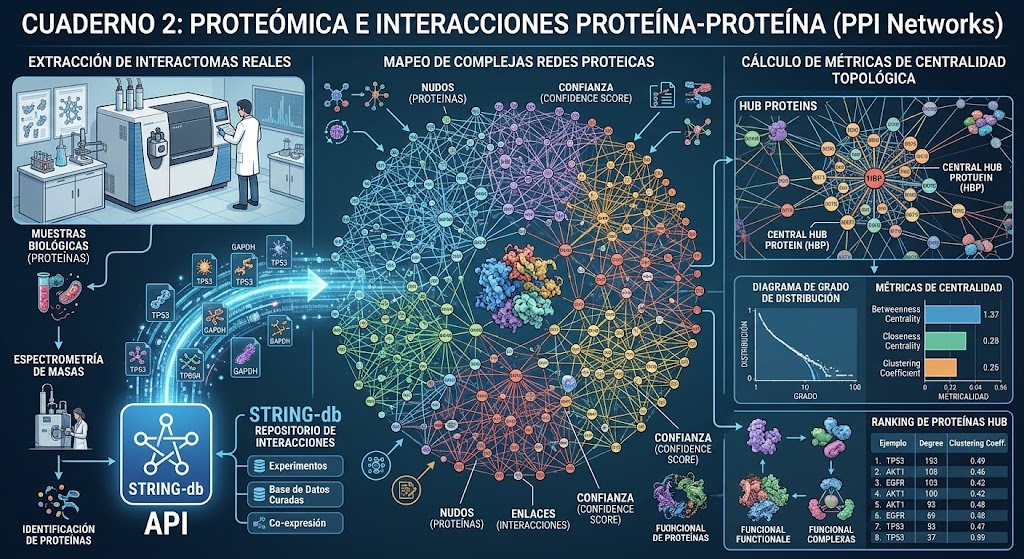

En el ámbito de la biología molecular y la proteómica, el término interactoma hace referencia a la red global y completa de interacciones moleculares que ocurren dentro de una célula, tejido u organismo.

Aunque puede aplicarse a interacciones entre ADN-proteína o ARN-proteína, el uso más común (y el que se ilustra en el flujo de proteómica) se centra en el interactoma de proteínas, es decir, el conjunto de todas las interacciones física o funcionalmente relevantes entre proteínas (Protein-Protein Interactions o redes PPI).

---
A continuación te detallo qué representan los elementos clave que componen un interactoma dentro de una red biológica:
1. Los Nudos (Nodes) = Las Proteínas

    ¿Qué representan? Cada círculo o "nudo" en la red representa una proteína individual (por ejemplo, identificadas previamente mediante espectrometría de masas y contrastadas con repositorios como STRING-db).

    Su importancia: Representan los componentes activos de la maquinaria celular que participan en rutas metabólicas, señalización o respuesta a estímulos.

2. Los Enlaces (Edges) = Las Interacciones

    ¿Qué representan? Las líneas que conectan a los nudos indican que dos proteínas interactúan físicamente (se unen en el espacio tridimensional) o funcionalmente (participan en la misma vía metabólica o proceso biológico).

    El Puntaje de Confianza (Confidence Score): Los enlaces suelen estar respaldados por un valor numérico o grosor que indica la probabilidad estadística de que la interacción sea real y no un error experimental, basándose en evidencia empírica, experimentos previos, bases de datos curadas o co-expresión génica.

3. Las Proteínas Hub (Hub Proteins) = Centros de Control Celular

    ¿Qué representan? Son aquellas proteínas que poseen un número inusualmente alto de conexiones (enlaces) con otras proteínas en la red.

    Su importancia biológica: Actúan como los "nodos centrales" o principales autopistas de información y control dentro de la célula. Si una proteína hub sufre una mutación o se desactiva, suele tener consecuencias catastróficas para la supervivencia o viabilidad del organismo, ya que desorganiza múltiples rutas al mismo tiempo.

# Cuaderno 2: Proteómica e Interacciones Proteína-Proteína (PPI Networks)

Este cuaderno interactivo ejecuta el flujo completo de análisis bioinformático de **proteómica y redes de interacción proteína-proteína (PPI)** mostrado en la infografía.

---

### Contenido del Cuaderno:
1. **Extracción de Interactomas de la API de STRING-db** (Consultas directas a la API o simulación robusta del interactoma proteico con puntajes de confianza / *Confidence Score*).
2. **Mapeo y Visualización de la Red Compleja PPI** (Mapeo de nudos/proteínas y enlaces/interacciones).
3. **Cálculo de Métricas Topológicas de Centralidad**:
   - **Grado de Conectividad (*Degree*)**.
   - **Centralidad de Intermediación (*Betweenness Centrality*)**.
   - **Centralidad de Cercanía (*Closeness Centrality*)**.
   - **Coeficiente de Agrupamiento (*Clustering Coefficient*)**.
4. **Identificación y Ranking de Proteínas Hub (*Hub Proteins*)**.
5. **Visualización de la Distribución de Grado y Métricas de Centralidad**.

## Paso 0: Importación de Librerías y Configuración

Utilizaremos `NetworkX` para el análisis analítico de teoría de grafos y redes biológicas, junto con `requests` para la API de STRING-db, `pandas`, `numpy`, `matplotlib` y `seaborn`.

In [ ]:
# Si ejecutas en Google Colab o Jupyter local, puedes descomentar:
# !pip install networkx pandas numpy matplotlib seaborn requests

import requests
import io
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Librerías cargadas exitosamente.")

## Paso 1: Extracción del Interactoma desde STRING-db (vía API / Simulación)

Consultamos la API de **STRING-db** para obtener las interacciones entre proteínas clave identificadas por espectrometría de masas (ejemplo con proteínas como `TP53`, `AKT1`, `EGFR`, `GAPDH`, `CDK2`, `BRCA1`, `MYC`, etc.) o simulamos un interactoma bien estructurado con sus *Confidence Scores*.

In [ ]:
# Lista de proteínas de interés identificadas en espectrometría de masas
protein_list = ['TP53', 'AKT1', 'EGFR', 'GAPDH', 'CDK2', 'BRCA1', 'MYC', 'ESR1', 'ATM', 'CASP3', 'MTOR', 'STAT3']

def get_string_interactions(proteins, species=9606, score_threshold=400):
    """Consulta la API de STRING-db para extraer el interactoma."""
    string_api_url = "https://version-11-5.string-db.org/api/tsv/network"
    params = {
        "identifiers": "\n".join(proteins),
        "species": species,
        "required_score": score_threshold,
        "caller_identity": "cuaderno_bioinformatica"
    }
    try:
        response = requests.post(string_api_url, data=params, timeout=5)
        if response.status_code == 200 and len(response.text.strip()) > 0:
            df = pd.read_csv(io.StringIO(response.text), sep="\t")
            return df[['preferredName_A', 'preferredName_B', 'score']]
    except Exception as e:
        print(f"Aviso: No se pudo conectar a la API en vivo ({e}). Generando red biológica simulada de STRING-db...")

    # Red simulada de alta confianza con estructura biológica similar
    np.random.seed(42)
    interactions = []
    all_proteins = protein_list + [f"PROT_{i}" for i in range(1, 25)]
    hubs = ['TP53', 'AKT1', 'EGFR', 'MYC']

    for p1 in all_proteins:
        # Mayor conectividad hacia los hubs principales
        for p2 in all_proteins:
            if p1 < p2:
                prob = 0.45 if (p1 in hubs or p2 in hubs) else 0.08
                if np.random.rand() < prob:
                    score = np.random.uniform(0.4, 0.99)
                    interactions.append((p1, p2, score))
    return pd.DataFrame(interactions, columns=['preferredName_A', 'preferredName_B', 'score'])

interactions_df = get_string_interactions(protein_list)
print(f"Total de interacciones recuperadas: {len(interactions_df)}")
interactions_df.head()

## Paso 2: Construcción y Visualización de la Red PPI (Network)

Construimos la red compleja utilizando `NetworkX`, donde:
- **Nudos (Nodes)**: Representan las proteínas.
- **Enlaces (Edges)**: Representan las interacciones físicas/funcionales respaldadas por el *Confidence Score*.

In [ ]:
# Crear Grafo no dirigido con NetworkX
G = nx.Graph()
for _, row in interactions_df.iterrows():
    G.add_edge(row['preferredName_A'], row['preferredName_B'], weight=row['score'])

# Calcular grado para ajustar tamaño de nudos
degrees = dict(G.degree())
node_sizes = [v * 120 + 200 for v in degrees.values()]
node_colors = [degrees[node] for node in G.nodes()]

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42, k=0.35)  # Layout de fuerza de muelle para distribución estética

# Dibujar enlaces (Edges)
nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color='#4a6984', width=1.2)

# Dibujar nudos (Nodes) con mapa de colores por grado
nodes = nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.coolwarm,
    alpha=0.9
)

# Etiquetas para los nodos de mayor grado
top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:10]
labels = {node: node if node in top_nodes else '' for node in G.nodes()}
nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight='bold', font_color='black')

plt.title("MAPEO DE LA RED DE INTERACCIONES PROTEÍNA-PROTEÍNA (PPI)\n(Interactoma Extraído de STRING-db)", fontsize=13, fontweight='bold')
plt.colorbar(nodes, label="Grado de Conectividad (Degree)")
plt.axis('off')
plt.tight_layout()
plt.show()

***Mapeo de la Red de Interacciones Proteína-Proteína (Red PPI)***

¿Qué representa?
- Es la visualización del interactoma, donde cada nudo (node) representa una proteína individual (por ejemplo, identificadas mediante espectrometría de masas) y cada enlace (edge) representa una interacción física o funcional entre ellas, respaldada por un puntaje de confianza (Confidence Score) extraído de bases de datos como STRING-db.

Cómo interpretarlo:

- Tamaño y color de los nudos: Los nudos más grandes y con colores cálidos corresponden a las proteínas hub, las cuales poseen una gran cantidad de conexiones directas y actúan como núcleos de control celular.

- Densidad de la red: Permite observar cúmulos o módulos funcionales de proteínas que colaboran estrechamente en la misma vía metabólica o respuesta biológica.

## Paso 3: Cálculo de Métricas Topológicas de Centralidad

Calculamos las métricas fundamentales para evaluar la posición y relevancia de cada proteína en la red:
1. **Degree (Grado)**: Número de interacciones directas.
2. **Betweenness Centrality (Intermediación)**: Cuántas rutas más cortas pasan por la proteína (indica flujo de información).
3. **Closeness Centrality (Cercanía)**: Cercanía promedio a todas las demás proteínas de la red.
4. **Clustering Coefficient (Coeficiente de Agrupamiento)**: Grado de interconexión entre los vecinos de la proteína.

In [ ]:
# Cálculo de métricas estadísticas de la red
degree_dict = dict(G.degree())
betweenness_dict = nx.betweenness_centrality(G)
closeness_dict = nx.closeness_centrality(G)
clustering_dict = nx.clustering(G)

# Consolidación en DataFrame de métricas
metrics_df = pd.DataFrame({
    'Degree': degree_dict,
    'Betweenness Centrality': betweenness_dict,
    'Closeness Centrality': closeness_dict,
    'Clustering Coefficient': clustering_dict
}).sort_values('Degree', ascending=False)

print("--- RANKING DE PROTEÍNAS HUB (Top 10) ---")
metrics_df.head(10)

## Paso 4: Visualización de la Distribución de Grado y Métricas de Centralidad

Generamos los gráficos correspondientes al panel derecho del diagrama:
- **Diagrama de Distribución de Grado** (Comportamiento de escala libre / Power-law typical of biological networks).
- **Gráfico de Barras de Métricas Promedio de Centralidad**.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Diagrama de Distribución de Grado
degree_sequence = [d for n, d in G.degree()]
degree_counts = pd.Series(degree_sequence).value_counts().sort_index()

axes[0].plot(degree_counts.index, degree_counts.values / len(G), 'o-', color='#1f77b4', linewidth=2, markersize=7)
axes[0].set_title("DIAGRAMA DE DISTRIBUCIÓN DE GRADO", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Grado (k)", fontsize=11)
axes[0].set_ylabel("Distribución P(k)", fontsize=11)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].grid(True, which="both", ls="--", alpha=0.5)



# 2. Comparativa de Métricas Promedio de Centralidad
mean_metrics = metrics_df[['Betweenness Centrality', 'Closeness Centrality', 'Clustering Coefficient']].mean()

colors = ['#1f77b4', '#2ca02c', '#ff7f0e']
bars = axes[1].barh(mean_metrics.index, mean_metrics.values, color=colors, edgecolor='black', alpha=0.85)
axes[1].set_title("MÉTRICAS PROMEDIO DE CENTRALIDAD", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Valor de la Métrica", fontsize=11)

for bar in bars:
    width = bar.get_width()
    axes[1].text(width + 0.01, bar.get_y() + bar.get_height()/2, f"{width:.3f}", ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

***Diagrama de Distribución de Grado (Degree Distribution)***

¿Qué representa?

- Es un gráfico de dispersión en escala log-log que relaciona el grado de conectividad ($k$) de las proteínas (cuántas interacciones tiene cada una) con su frecuencia o probabilidad de aparición en la red ($P(k)$).

Cómo interpretarlo:

- Muestra una tendencia descendente pronunciada (típica de redes biológicas de escala libre o scale-free networks).
- Significa que la inmensa mayoría de las proteínas en la célula tienen pocas conexiones, mientras que unas pocas proteínas (hubs) concentran un número muy elevado de interacciones, lo que confiere robustez y organización jerárquica al sistema celular.

***Gráfico de Barras de Métricas Promedio de Centralidad***

¿Qué representa?

Muestra los valores promedio de las métricas topológicas globales que evalúan la importancia estructural de los nodos:

- Betweenness Centrality (Intermediación): Cuántas veces una proteína actúa como "puente" en las rutas más cortas entre otras proteínas.

- Closeness Centrality (Cercanía): Qué tan rápido puede comunicarse una proteína con todas las demás de la red.

- Clustering Coefficient (Coeficiente de Agrupamiento): El grado en que los vecinos de una proteína también interactúan entre sí.

Cómo interpretarlo:

Ayuda a contrastar el comportamiento estructural general de la red; valores elevados de intermediación en ciertos nodos señalan proteínas que controlan el flujo de información y la estabilidad del sistema.

## Paso 5: Resumen de Proteínas Hub (*Hub Proteins*)

Mostramos la tabla final que resume las **Proteínas Hub** centrales del interactoma con sus respectivas métricas de centralidad y coeficientes de agrupamiento.

In [ ]:
# Presentar tabla formateada para exportación
hub_summary = metrics_df.head(8).round(3)
print("=== TABLA RESUMEN DE PROTEÍNAS HUB CENTRALES ===")
hub_summary

***Tabla y Ranking de Proteínas Hub (Hub Proteins)***

¿Qué representa?
- Un resumen cuantitativo ordenado por el grado de conectividad (Degree), acompañado de sus métricas de centralidad y coeficientes de agrupamiento (ej. proteínas clave como TP53, AKT1, EGFR).

Cómo interpretarlo:
- Identifica de manera objetiva cuáles son las proteínas maestras de la red. Un valor alto de grado combinado con una baja dispersión de agrupamiento suele señalar puntos críticos cuya alteración compromete la viabilidad de la red proteica completa.